# Notebook 1: Logits, Softmax, and Temperature

## How LLMs Build a Probability Distribution Over Tokens

Before we touch a real language model, let's understand the **math** that converts raw model outputs into token probabilities.

**Key concepts:**
- **Logits**: Raw, unnormalized scores the model outputs for each token in its vocabulary
- **Softmax**: The function that converts logits into a valid probability distribution
- **Temperature**: A parameter that controls how "peaked" or "flat" the distribution is

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## What Are Logits?

An LLM's final layer outputs a vector of **logits** — one score per token in its vocabulary. These are raw, unnormalized values that can be any real number (positive, negative, or zero).

Think of logits as the model's "confidence scores" before normalization. Higher logit = model thinks this token is more likely.

Let's simulate a tiny vocabulary of 8 tokens and see what logits look like:

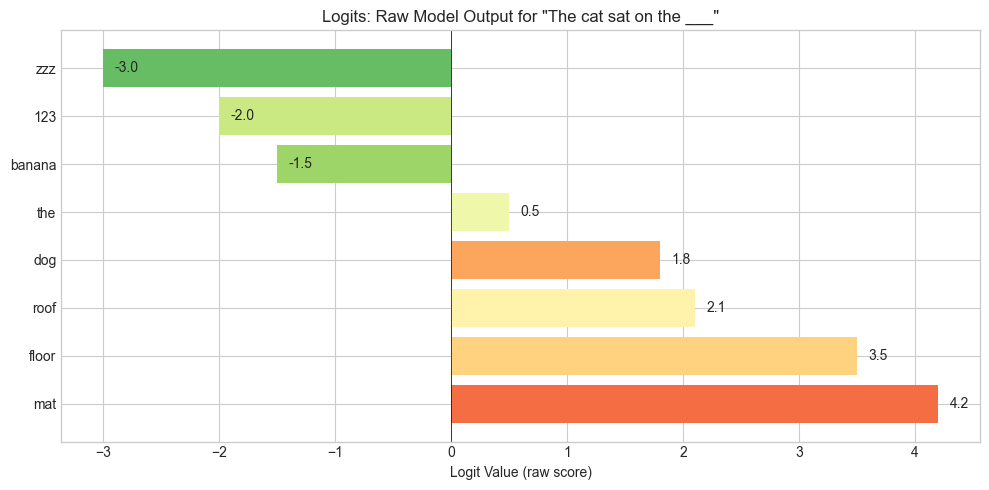

Logit values: [4.199999809265137, 1.7999999523162842, 3.5, 2.0999999046325684, 0.5, -2.0, -1.5, -3.0]
Sum of logits: 5.60  (NOT 1.0 — these aren't probabilities yet!)
Any negatives? True  (logits can be any real number)


In [2]:
# Simulate logits for a tiny vocabulary
# Imagine the prompt is: "The cat sat on the ___"
tokens = ["mat", "dog", "floor", "roof", "the", "123", "banana", "zzz"]
logits = torch.tensor([4.2, 1.8, 3.5, 2.1, 0.5, -2.0, -1.5, -3.0])

fig, ax = plt.subplots()
colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(tokens)))
# Sort by logit value for clearer visualization
sorted_indices = torch.argsort(logits, descending=True)
sorted_tokens = [tokens[i] for i in sorted_indices]
sorted_logits = logits[sorted_indices]
sorted_colors = colors[sorted_indices.numpy()]

bars = ax.barh(sorted_tokens, sorted_logits.numpy(), color=sorted_colors)
ax.set_xlabel("Logit Value (raw score)")
ax.set_title('Logits: Raw Model Output for "The cat sat on the ___"')
ax.axvline(x=0, color="black", linewidth=0.5)

for bar, val in zip(bars, sorted_logits):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Logit values: {logits.tolist()}")
print(f"Sum of logits: {logits.sum().item():.2f}  (NOT 1.0 — these aren't probabilities yet!)")
print(f"Any negatives? {(logits < 0).any().item()}  (logits can be any real number)")

## The Softmax Function

Logits aren't probabilities — they don't sum to 1 and can be negative. We need **softmax** to convert them:

$$P(token_i) = \frac{e^{z_i}}{\sum_{j=1}^{V} e^{z_j}}$$

Where:
- $z_i$ is the logit for token $i$
- $V$ is the vocabulary size
- $e^{z_i}$ makes everything positive (exponential is always > 0)
- Dividing by the sum ensures everything adds to 1

**Why exponential?** It preserves the ordering (higher logit → higher probability) while amplifying differences between scores.

In [3]:
# Step-by-step softmax computation
print("=== Softmax Step by Step ===\n")

# Step 1: Exponentiate each logit
exp_logits = torch.exp(logits)
print("Step 1 — Exponentiate (e^z):")
for t, l, e in zip(tokens, logits, exp_logits):
    print(f"  {t:>8s}: e^{l:.1f} = {e:.4f}")

# Step 2: Sum of exponentials
exp_sum = exp_logits.sum()
print(f"\nStep 2 — Sum of all exponentials: {exp_sum:.4f}")

# Step 3: Divide each by the sum
probs = exp_logits / exp_sum
print(f"\nStep 3 — Divide each by sum to get probabilities:")
for t, p in zip(tokens, probs):
    print(f"  {t:>8s}: {p:.4f}  ({p*100:.1f}%)")

print(f"\nSum of probabilities: {probs.sum().item():.6f}  (= 1.0 ✓)")

# Verify against PyTorch's softmax
probs_pytorch = F.softmax(logits, dim=0)
assert torch.allclose(probs, probs_pytorch), "Mismatch!"
print("Matches torch.nn.functional.softmax ✓")

=== Softmax Step by Step ===

Step 1 — Exponentiate (e^z):
       mat: e^4.2 = 66.6863
       dog: e^1.8 = 6.0496
     floor: e^3.5 = 33.1155
      roof: e^2.1 = 8.1662
       the: e^0.5 = 1.6487
       123: e^-2.0 = 0.1353
    banana: e^-1.5 = 0.2231
       zzz: e^-3.0 = 0.0498

Step 2 — Sum of all exponentials: 116.0746

Step 3 — Divide each by sum to get probabilities:
       mat: 0.5745  (57.5%)
       dog: 0.0521  (5.2%)
     floor: 0.2853  (28.5%)
      roof: 0.0704  (7.0%)
       the: 0.0142  (1.4%)
       123: 0.0012  (0.1%)
    banana: 0.0019  (0.2%)
       zzz: 0.0004  (0.0%)

Sum of probabilities: 1.000000  (= 1.0 ✓)
Matches torch.nn.functional.softmax ✓


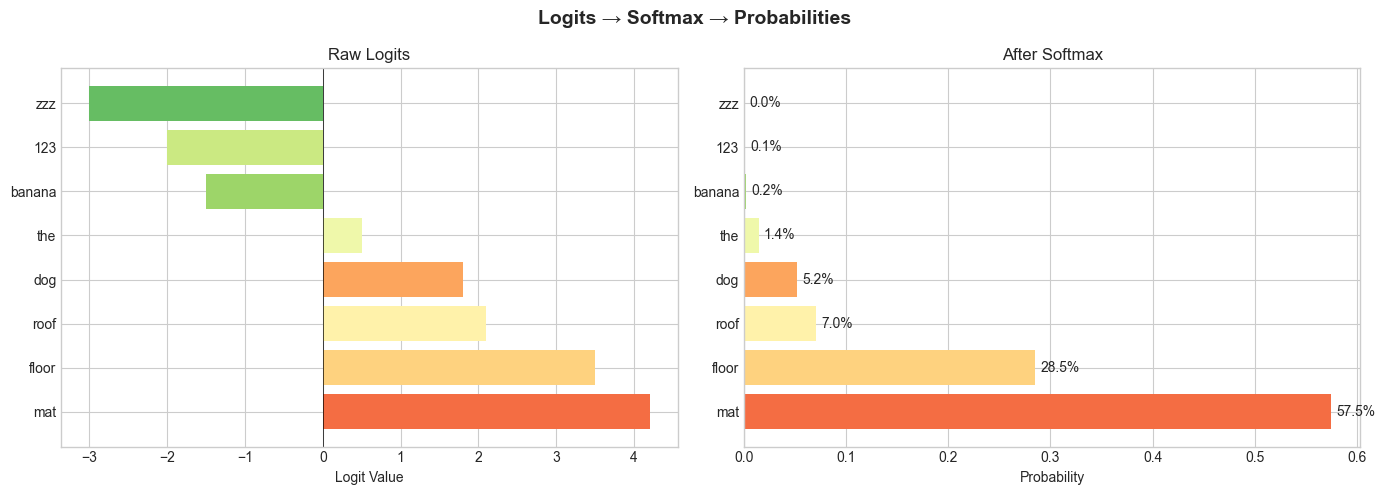

In [4]:
# Visualize: logits vs probabilities side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sorted_probs = probs[sorted_indices]

ax1.barh(sorted_tokens, sorted_logits.numpy(), color=sorted_colors)
ax1.set_xlabel("Logit Value")
ax1.set_title("Raw Logits")
ax1.axvline(x=0, color="black", linewidth=0.5)

ax2.barh(sorted_tokens, sorted_probs.numpy(), color=sorted_colors)
ax2.set_xlabel("Probability")
ax2.set_title("After Softmax")
for bar, val in zip(ax2.patches, sorted_probs):
    ax2.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
             f"{val:.1%}", va="center", fontsize=10)

fig.suptitle("Logits → Softmax → Probabilities", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Temperature Scaling

Temperature ($T$) is applied **before** softmax to control the "sharpness" of the distribution:

$$P(token_i) = \frac{e^{z_i / T}}{\sum_{j=1}^{V} e^{z_j / T}}$$

| Temperature | Effect | Use Case |
|---|---|---|
| $T < 1$ (e.g., 0.1) | Sharper — amplifies differences, concentrates probability on top tokens | Factual Q&A, code generation |
| $T = 1$ | Default — uses logits as-is | General purpose |
| $T > 1$ (e.g., 2.0) | Flatter — smooths differences, spreads probability more evenly | Creative writing, brainstorming |
| $T → 0$ | Approaches greedy (argmax) — always picks the highest logit | Deterministic output |
| $T → ∞$ | Approaches uniform random — all tokens equally likely | Maximum randomness |

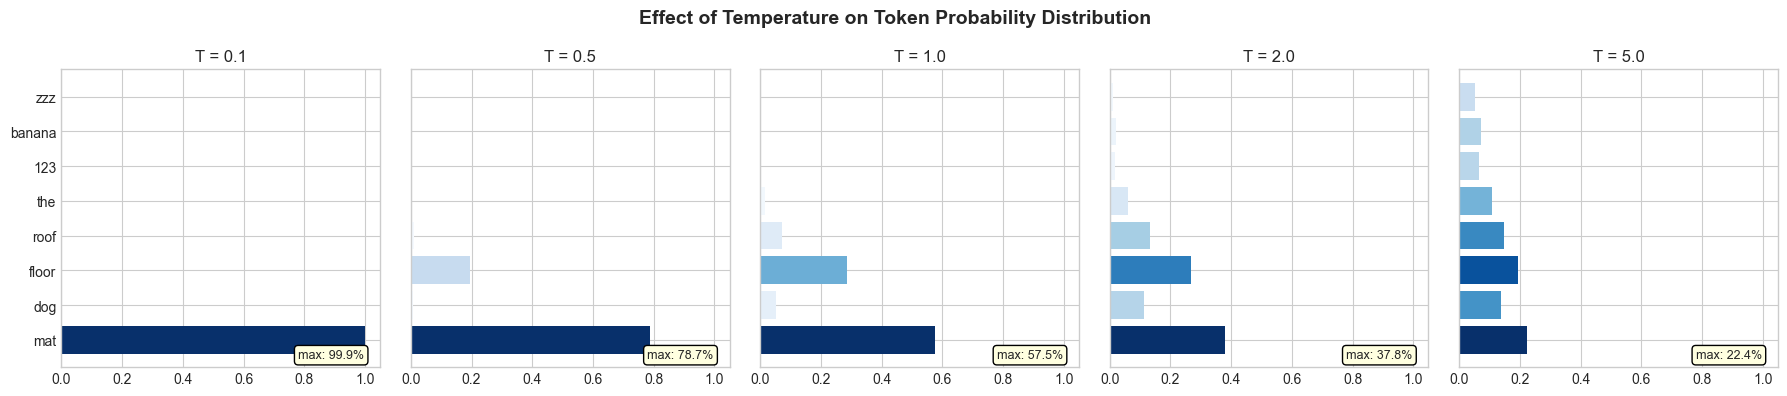

   Token  T=0.1   T=0.5   T=1.0   T=2.0   T=5.0 
-------------------------------------------------------
     mat  99.9%  78.7%  57.5%  37.8%  22.4%
     dog   0.0%   0.6%   5.2%  11.4%  13.8%
   floor   0.1%  19.4%  28.5%  26.7%  19.5%
    roof   0.0%   1.2%   7.0%  13.2%  14.7%
     the   0.0%   0.0%   1.4%   5.9%  10.7%
     123   0.0%   0.0%   0.1%   1.7%   6.5%
  banana   0.0%   0.0%   0.2%   2.2%   7.2%
     zzz   0.0%   0.0%   0.0%   1.0%   5.3%


In [5]:
# Temperature scaling demonstration
temperatures = [0.1, 0.5, 1.0, 2.0, 5.0]

fig, axes = plt.subplots(1, len(temperatures), figsize=(18, 4), sharey=True)

for ax, temp in zip(axes, temperatures):
    scaled_logits = logits / temp
    temp_probs = F.softmax(scaled_logits, dim=0)
    
    colors_temp = plt.cm.Blues(temp_probs.numpy() / temp_probs.max().item())
    ax.barh(tokens, temp_probs.numpy(), color=colors_temp)
    ax.set_title(f"T = {temp}")
    ax.set_xlim(0, 1.05)
    
    # Show the top token probability
    top_prob = temp_probs.max().item()
    ax.text(0.95, 0.02, f"max: {top_prob:.1%}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow"))

fig.suptitle("Effect of Temperature on Token Probability Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Print numerical comparison
print(f"{'Token':>8s}", end="")
for t in temperatures:
    print(f"  T={t:<4}", end="")
print()
print("-" * 55)
for i, token in enumerate(tokens):
    print(f"{token:>8s}", end="")
    for temp in temperatures:
        p = F.softmax(logits / temp, dim=0)[i].item()
        print(f"  {p:5.1%}", end="")
    print()

## Log Probabilities (Log-Probs)

In practice, APIs and models often return **log probabilities** instead of raw probabilities. Why?

1. **Numerical stability**: Probabilities can be astronomically small (e.g., $10^{-30}$). Logs keep values manageable.
2. **Easy multiplication**: To get the probability of a sequence, you multiply token probabilities. In log space, multiplication becomes addition: $\log(P(A) \cdot P(B)) = \log P(A) + \log P(B)$
3. **Direct from softmax**: Log-softmax is numerically more stable than softmax followed by log.

In [6]:
# Log probabilities
log_probs = F.log_softmax(logits, dim=0)

print("=== Probabilities vs Log-Probabilities ===\n")
print(f"{'Token':>8s}  {'Prob':>8s}  {'Log-Prob':>10s}  {'Back to Prob':>12s}")
print("-" * 45)
for t, p, lp in zip(tokens, probs, log_probs):
    print(f"{t:>8s}  {p:8.4f}  {lp:10.4f}  {torch.exp(lp):12.4f}")

print(f"\n--- Sequence probability example ---")
print(f'If model generates "mat" then "floor":')
print(f"  P(mat) = {probs[0]:.4f}, P(floor) = {probs[2]:.4f}")
print(f"  P(sequence) = {probs[0]:.4f} × {probs[2]:.4f} = {probs[0] * probs[2]:.6f}")
print(f"  log P(sequence) = {log_probs[0]:.4f} + {log_probs[2]:.4f} = {log_probs[0] + log_probs[2]:.4f}")
print(f"  Verify: exp({log_probs[0] + log_probs[2]:.4f}) = {torch.exp(log_probs[0] + log_probs[2]):.6f} ✓")

=== Probabilities vs Log-Probabilities ===

   Token      Prob    Log-Prob  Back to Prob
---------------------------------------------
     mat    0.5745     -0.5542        0.5745
     dog    0.0521     -2.9542        0.0521
   floor    0.2853     -1.2542        0.2853
    roof    0.0704     -2.6542        0.0704
     the    0.0142     -4.2542        0.0142
     123    0.0012     -6.7542        0.0012
  banana    0.0019     -6.2542        0.0019
     zzz    0.0004     -7.7542        0.0004

--- Sequence probability example ---
If model generates "mat" then "floor":
  P(mat) = 0.5745, P(floor) = 0.2853
  P(sequence) = 0.5745 × 0.2853 = 0.163905
  log P(sequence) = -0.5542 + -1.2542 = -1.8085
  Verify: exp(-1.8085) = 0.163905 ✓


## Scaling to Real Vocabulary Sizes

Real LLMs have vocabularies of 32K–128K+ tokens. Let's see what this looks like — most of the probability mass concentrates on a tiny fraction of the vocabulary.

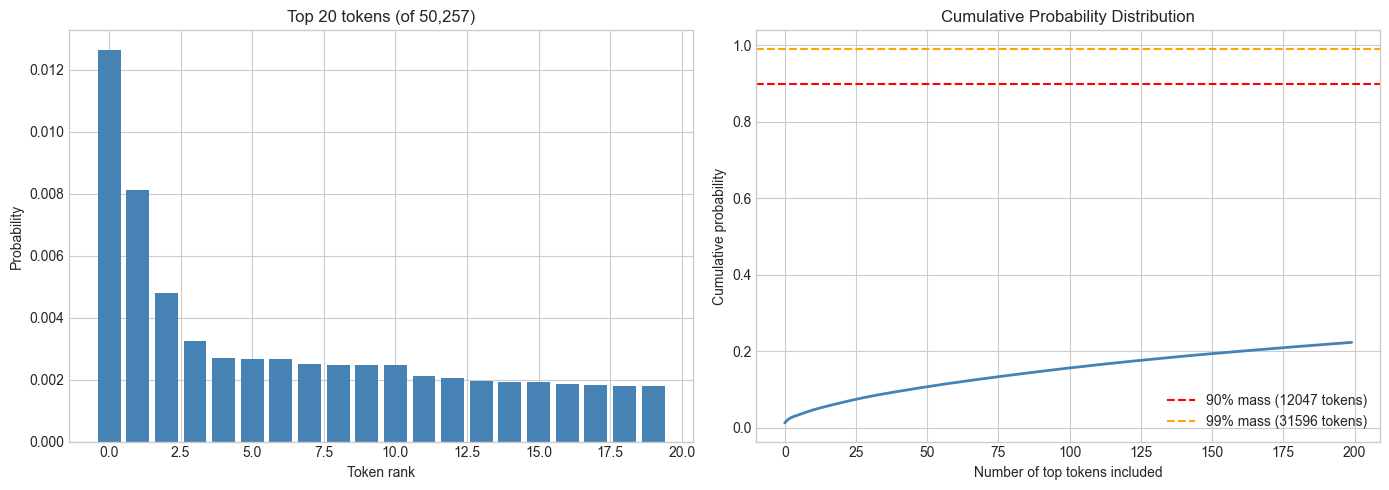

Vocabulary size: 50,257
Top 1 token holds: 1.3% of probability mass
Top 10 tokens hold: 4.4%
Tokens needed for 90%: 12047 (23.97% of vocab)
Tokens needed for 99%: 31596 (62.87% of vocab)


In [7]:
# Simulating a realistic vocabulary size
torch.manual_seed(42)
vocab_size = 50257  # GPT-2's vocabulary size
realistic_logits = torch.randn(vocab_size) * 2  # Random logits, std=2

# Make a few tokens clearly preferred (simulating a confident prediction)
realistic_logits[1000] = 8.0   # "strong" candidate
realistic_logits[2500] = 6.5   # "good" candidate
realistic_logits[400] = 5.0    # "decent" candidate

realistic_probs = F.softmax(realistic_logits, dim=0)
sorted_probs, sorted_indices = torch.sort(realistic_probs, descending=True)

# How many tokens hold 90% of the probability?
cumsum = torch.cumsum(sorted_probs, dim=0)
tokens_for_90 = (cumsum < 0.90).sum().item() + 1
tokens_for_99 = (cumsum < 0.99).sum().item() + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: top 20 tokens
ax1.bar(range(20), sorted_probs[:20].numpy(), color="steelblue")
ax1.set_xlabel("Token rank")
ax1.set_ylabel("Probability")
ax1.set_title(f"Top 20 tokens (of {vocab_size:,})")

# Right: cumulative distribution
ax2.plot(range(200), cumsum[:200].numpy(), color="steelblue", linewidth=2)
ax2.axhline(y=0.9, color="red", linestyle="--", label=f"90% mass ({tokens_for_90} tokens)")
ax2.axhline(y=0.99, color="orange", linestyle="--", label=f"99% mass ({tokens_for_99} tokens)")
ax2.set_xlabel("Number of top tokens included")
ax2.set_ylabel("Cumulative probability")
ax2.set_title("Cumulative Probability Distribution")
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Vocabulary size: {vocab_size:,}")
print(f"Top 1 token holds: {sorted_probs[0]:.1%} of probability mass")
print(f"Top 10 tokens hold: {sorted_probs[:10].sum():.1%}")
print(f"Tokens needed for 90%: {tokens_for_90} ({tokens_for_90/vocab_size:.2%} of vocab)")
print(f"Tokens needed for 99%: {tokens_for_99} ({tokens_for_99/vocab_size:.2%} of vocab)")

## Key Takeaways

1. **Logits** are raw scores — one per vocabulary token — that come from the model's final layer
2. **Softmax** converts logits into a proper probability distribution (all positive, sums to 1)
3. **Temperature** reshapes the distribution: low T = confident/peaked, high T = uncertain/flat
4. **Log-probabilities** are preferred in practice for numerical stability and efficient sequence scoring
5. In real models, the vast majority of probability mass concentrates on a **tiny fraction** of the vocabulary

**Next up:** We'll see how a real model (GPT-2) produces these logits from actual text input.